# Python机器学习基础教程 ch03：无监督学习与预处理

对应笔记 [ch03.md](../ch03.md)。本 notebook 是**分节跟随代码**：小节结构与笔记一致，完整讲解、原书插图与“坑与陷阱”请看笔记页面。

运行环境：`machinelearn`（Python 3.10 / scikit-learn 1.7 / pandas 2.3 / mglearn，mglearn 已打 boston 本地数据补丁）。原书 0.19 时代 API 的适配处在代码注释中以 **版本适配** 标出，与笔记中的“版本差异” admonition 一一对应。

In [1]:
# ===== 公共设置（notebook 版新增；原书在 Jupyter 全局环境中运行）=====
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mglearn

# 兜底：nbclient/nbconvert 实跑时 inline 后端的 flush_figures 钩子未注册，
# 图会留在内存不进输出——这里手动补一个“每个 cell 结束时把打开的图显示出来”
import IPython
_ip = IPython.get_ipython()
if _ip is not None:
    def _flush_figs():
        if plt.get_fignums():
            plt.show()
    _ip.events.register("post_execute", _flush_figs)

print("sklearn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__)

sklearn 1.7.0 | pandas 2.3.3 | numpy 2.2.6


**本章解决**：没有标签的数据能做什么？两条线：一是**数据变换**——把数据换成一种更好用的表示（缩放、PCA 降维、NMF 特征提取、t-SNE 可视化），二是**聚类**——把相似的数据自动分成组（k 均值、凝聚聚类、DBSCAN）。这一章也是第 2 章监督学习的"后勤部队"：缩放和降维经常作为监督算法的预处理步骤，能直接抬高模型精度（本章你将亲眼看到 SVC 精度从 0.63 跳到 0.97）。第 2 章讲了监督学习 API（fit/predict/score），本章补上另一半：fit/transform 的预处理 API。

## 3.1 无监督学习的类型

本章研究两种类型的无监督学习：**数据集变换**与**聚类**。

## 3.2 无监督学习的挑战

无监督学习的一个主要挑战：**评估算法是否学到了有用的东西**。无监督算法一般用于不含任何标签信息的数据，所以不知道正确的输出是什么，很难判断一个模型是否"表现很好"。

## 3.3 预处理与缩放

第 2 章说过，一些算法（如**神经网络**和 **SVM**）对数据缩放非常敏感。所以通常的做法是对特征进行调节，使数据表示更适合这些算法。本质上就是对数据做简单的**按特征的缩放和移动**。下面一行代码画出本章最重要的总览图：

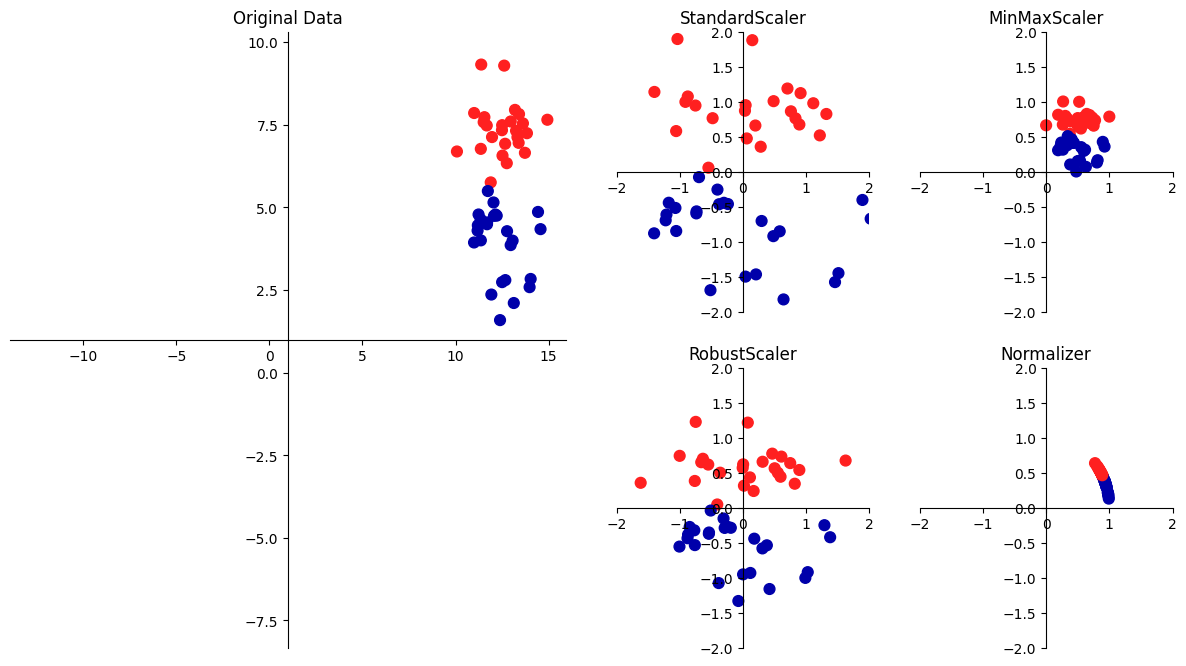

In [2]:
# ===== 书 3.3 节：四种缩放方法总览 =====
mglearn.plots.plot_scaling()

### 3.3.1 不同类型的预处理

图 3-1 的第一张图是一个模拟的两特征二分类数据集：第一个特征（x 轴）位于 10 到 15 之间，第二个特征（y 轴）大约位于 1 到 9 之间——**两个特征的量纲尺度差了一个数量级**。接下来四张图展示四种变换，都生成了更"标准"的范围：

### 3.3.2 应用数据变换

用 scikit-learn 实际做一遍。数据用第 2 章的 **cancer 数据集**（569 个数据点，每个 30 个测量值）。场景：想先把数据用 MinMaxScaler 预处理，再跑核 SVM（SVC）。第一步，加载数据并划分训练/测试集（需要分开的数据来评估预处理后构建的监督模型），然后导入实现预处理的类并实例化：

In [3]:
# ===== 书 3.3.2 节：加载数据 + 实例化缩放器 =====
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
cancer = load_breast_cancer()

X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target,
                                                    random_state=1)
print(X_train.shape)   # (426, 30)
print(X_test.shape)    # (143, 30)

scaler = MinMaxScaler()

(426, 30)
(143, 30)


In [4]:
# ===== 书 3.3.2 节：fit 只需要 X =====
scaler.fit(X_train)

,feature_range,"(0, ...)"
,copy,True
,clip,False


In [5]:
# ===== 书 3.3.2 节：transform 训练数据并检查 =====
X_train_scaled = scaler.transform(X_train)
# 在缩放之前和之后分别打印数据集属性
print("transformed shape: {}".format(X_train_scaled.shape))
print("per-feature minimum before scaling:\n {}".format(X_train.min(axis=0)))
print("per-feature maximum before scaling:\n {}".format(X_train.max(axis=0)))
print("per-feature minimum after scaling:\n {}".format(
    X_train_scaled.min(axis=0)))
print("per-feature maximum after scaling:\n {}".format(
    X_train_scaled.max(axis=0)))

transformed shape: (426, 30)
per-feature minimum before scaling:
 [6.981e+00 9.710e+00 4.379e+01 1.435e+02 5.263e-02 1.938e-02 0.000e+00
 0.000e+00 1.060e-01 5.024e-02 1.153e-01 3.602e-01 7.570e-01 6.802e+00
 1.713e-03 2.252e-03 0.000e+00 0.000e+00 9.539e-03 8.948e-04 7.930e+00
 1.202e+01 5.041e+01 1.852e+02 7.117e-02 2.729e-02 0.000e+00 0.000e+00
 1.566e-01 5.521e-02]
per-feature maximum before scaling:
 [2.811e+01 3.928e+01 1.885e+02 2.501e+03 1.634e-01 2.867e-01 4.268e-01
 2.012e-01 3.040e-01 9.575e-02 2.873e+00 4.885e+00 2.198e+01 5.422e+02
 3.113e-02 1.354e-01 3.960e-01 5.279e-02 6.146e-02 2.984e-02 3.604e+01
 4.954e+01 2.512e+02 4.254e+03 2.226e-01 9.379e-01 1.170e+00 2.910e-01
 5.774e-01 1.486e-01]
per-feature minimum after scaling:
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
per-feature maximum after scaling:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


In [6]:
# ===== 书 3.3.2 节：transform 测试数据 =====
X_test_scaled = scaler.transform(X_test)
# 在缩放之后打印测试数据的属性
print("per-feature minimum after scaling:\n{}".format(X_test_scaled.min(axis=0)))
print("per-feature maximum after scaling:\n{}".format(X_test_scaled.max(axis=0)))

per-feature minimum after scaling:
[ 0.0336031   0.0226581   0.03144219  0.01141039  0.14128374  0.04406704
  0.          0.          0.1540404  -0.00615249 -0.00137796  0.00594501
  0.00430665  0.00079567  0.03919502  0.0112206   0.          0.
 -0.03191387  0.00664013  0.02660975  0.05810235  0.02031974  0.00943767
  0.1094235   0.02637792  0.          0.         -0.00023764 -0.00182032]
per-feature maximum after scaling:
[0.9578778  0.81501522 0.95577362 0.89353128 0.81132075 1.21958701
 0.87956888 0.9333996  0.93232323 1.0371347  0.42669616 0.49765736
 0.44117231 0.28371044 0.48703131 0.73863671 0.76717172 0.62928585
 1.33685792 0.39057253 0.89612238 0.79317697 0.84859804 0.74488793
 0.9154725  1.13188961 1.07008547 0.92371134 1.20532319 1.63068851]


### 3.3.3 对训练数据和测试数据进行相同的缩放

为了让监督模型能在测试集上运行，对训练集和测试集应用**完全相同的变换**非常重要。如果反过来对测试集单独 fit 一次，会发生什么？下面用图 3-2 演示：

In [7]:
# ===== 书 3.3.3 节：正确缩放 vs 错误缩放 =====
from sklearn.datasets import make_blobs
# 构造数据
X, _ = make_blobs(n_samples=50, centers=5, random_state=4, cluster_std=2)
# 将其分为训练集和测试集
X_train, X_test = train_test_split(X, random_state=5, test_size=.1)

# 正确做法：fit 作用在训练集上，transform 作用在训练集和测试集上
scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 错误做法：单独对测试集进行缩放，使得测试集的最小值为0、最大值为1
# 千万不要这么做！这里只是为了举例
test_scaler = MinMaxScaler()
test_scaler.fit(X_test)
X_test_scaled_badly = test_scaler.transform(X_test)
# （原书接着用三联散点图可视化上述三种数据，对应图 3-2）

In [8]:
# ===== 书 3.3.3 节 侧栏：fit_transform =====
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
# 依次调用fit和transform（使用方法链）
X_scaled = scaler.fit(X).transform(X)
# 结果相同，但计算更加高效
X_scaled_d = scaler.fit_transform(X)

### 3.3.4 预处理对监督学习的作用

回到 cancer 数据集，观察 MinMaxScaler 对 SVC 的实际作用。先在原始数据上拟合 SVC 作对比，再用两种缩放器分别预处理后重训：

In [9]:
# ===== 书 3.3.4 节：未缩放 vs 缩放后的 SVC =====
from sklearn.svm import SVC

X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target,
                                                    random_state=0)

svm = SVC(C=100)
svm.fit(X_train, y_train)
print("Test set accuracy: {:.2f}".format(svm.score(X_test, y_test)))
# → 0.63（未缩放）

# 使用0-1缩放进行预处理
scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
svm.fit(X_train_scaled, y_train)
print("Scaled test set accuracy: {:.2f}".format(
    svm.score(X_test_scaled, y_test)))
# → 0.97（MinMaxScaler 缩放后）

# 换用零均值单位方差的缩放方法，接口相同，只需改类名
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
svm.fit(X_train_scaled, y_train)
print("SVM test accuracy: {:.2f}".format(svm.score(X_test_scaled, y_test)))
# → 0.96（StandardScaler 缩放后）

Test set accuracy: 0.94
Scaled test set accuracy: 0.97
SVM test accuracy: 0.96


## 3.4 降维、特征提取与流形学习

利用无监督学习进行数据变换的目的很多，最常见的三个：**可视化**、**压缩数据**，以及**寻找信息量更大的数据表示**以用于进一步处理。

### 3.4.1 主成分分析

**主成分分析（principal component analysis, PCA）**是一种**旋转数据集**的方法，旋转后的特征在统计上不相关。做完旋转之后，通常根据新特征对解释数据的重要性来**选择它的一个子集**。下面这个例子展示 PCA 对模拟二维数据集的作用：

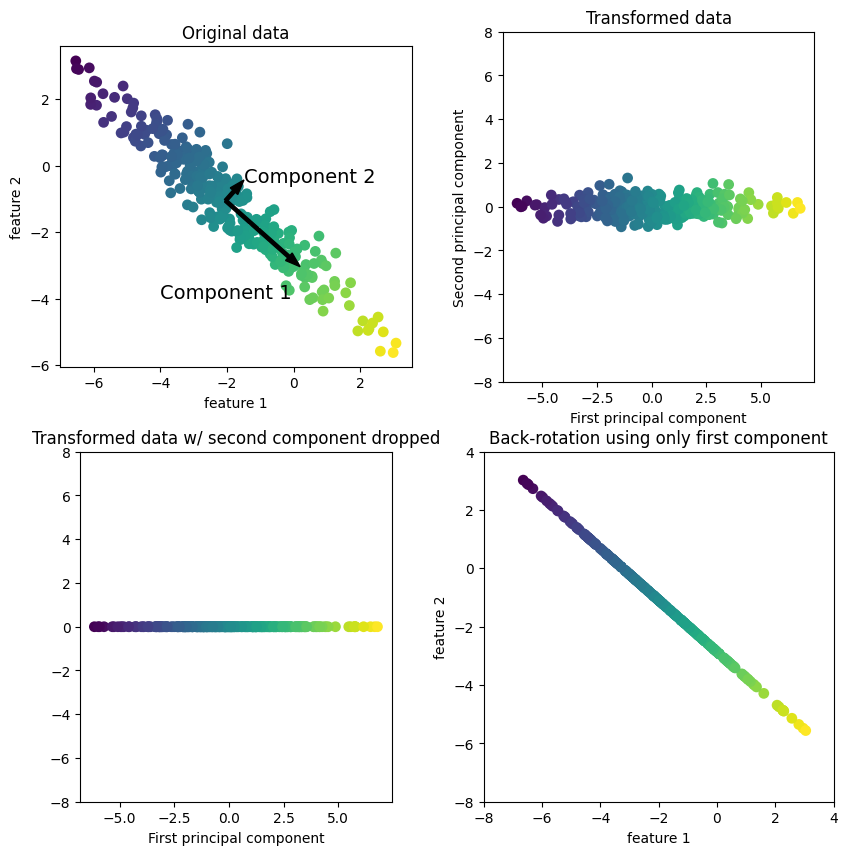

In [10]:
# ===== 书 3.4.1 节：PCA 图解 =====
mglearn.plots.plot_pca_illustration()

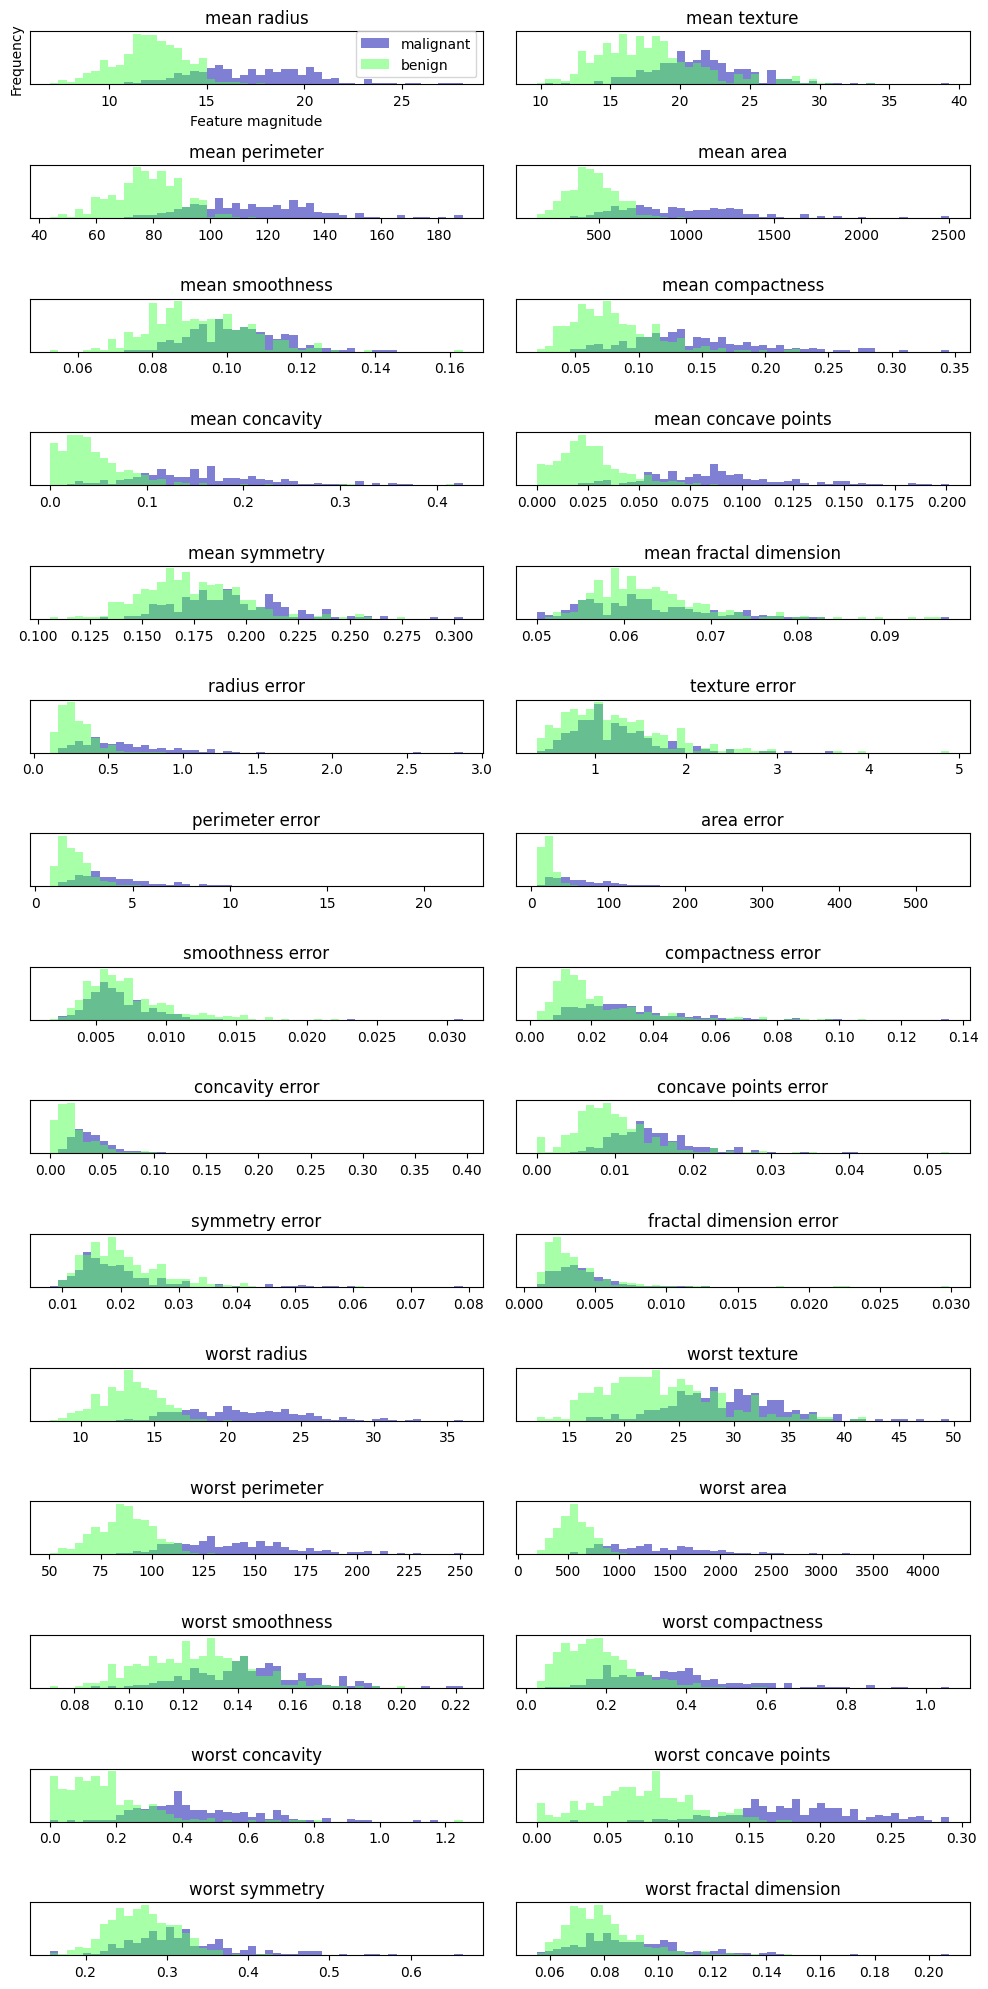

In [11]:
# ===== 书 3.4.1 节：cancer 每特征的类别直方图 =====
fig, axes = plt.subplots(15, 2, figsize=(10, 20))
malignant = cancer.data[cancer.target == 0]
benign = cancer.data[cancer.target == 1]

ax = axes.ravel()

for i in range(30):
    _, bins = np.histogram(cancer.data[:, i], bins=50)
    ax[i].hist(malignant[:, i], bins=bins, color=mglearn.cm3(0), alpha=.5)
    ax[i].hist(benign[:, i], bins=bins, color=mglearn.cm3(2), alpha=.5)
    ax[i].set_title(cancer.feature_names[i])
    ax[i].set_yticks(())
ax[0].set_xlabel("Feature magnitude")
ax[0].set_ylabel("Frequency")
ax[0].legend(["malignant", "benign"], loc="best")
fig.tight_layout()

Original shape: (569, 30)
Reduced shape: (569, 2)


Text(0, 0.5, 'Second principal component')

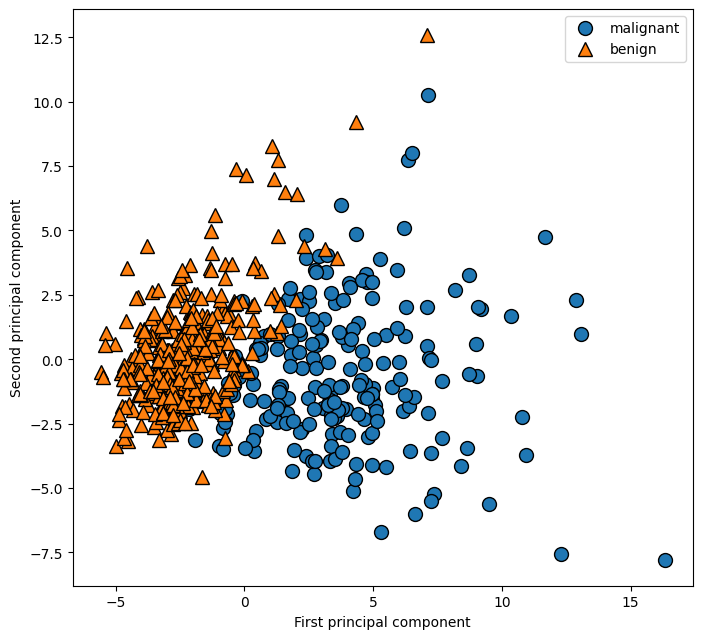

In [12]:
# ===== 书 3.4.1 节：先缩放再 PCA 降维 =====
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
cancer = load_breast_cancer()

scaler = StandardScaler()
scaler.fit(cancer.data)
X_scaled = scaler.transform(cancer.data)

# 保留数据的前两个主成分
pca = PCA(n_components=2)
# 对乳腺癌数据拟合PCA模型
pca.fit(X_scaled)

# 将数据变换到前两个主成分的方向上
X_pca = pca.transform(X_scaled)
print("Original shape: {}".format(str(X_scaled.shape)))   # (569, 30)
print("Reduced shape: {}".format(str(X_pca.shape)))       # (569, 2)

# 对第一个和第二个主成分作图，按类别着色
plt.figure(figsize=(8, 8))
mglearn.discrete_scatter(X_pca[:, 0], X_pca[:, 1], cancer.target)
plt.legend(cancer.target_names, loc="best")
plt.gca().set_aspect("equal")
plt.xlabel("First principal component")
plt.ylabel("Second principal component")

PCA component shape: (2, 30)
PCA components:
[[ 0.21890244  0.10372458  0.22753729  0.22099499  0.14258969  0.23928535
   0.25840048  0.26085376  0.13816696  0.06436335  0.20597878  0.01742803
   0.21132592  0.20286964  0.01453145  0.17039345  0.15358979  0.1834174
   0.04249842  0.10256832  0.22799663  0.10446933  0.23663968  0.22487053
   0.12795256  0.21009588  0.22876753  0.25088597  0.12290456  0.13178394]
 [-0.23385713 -0.05970609 -0.21518136 -0.23107671  0.18611302  0.15189161
   0.06016536 -0.0347675   0.19034877  0.36657547 -0.10555215  0.08997968
  -0.08945723 -0.15229263  0.20443045  0.2327159   0.19720728  0.13032156
   0.183848    0.28009203 -0.21986638 -0.0454673  -0.19987843 -0.21935186
   0.17230435  0.14359317  0.09796411 -0.00825724  0.14188335  0.27533947]]


Text(0, 0.5, 'Principal components')

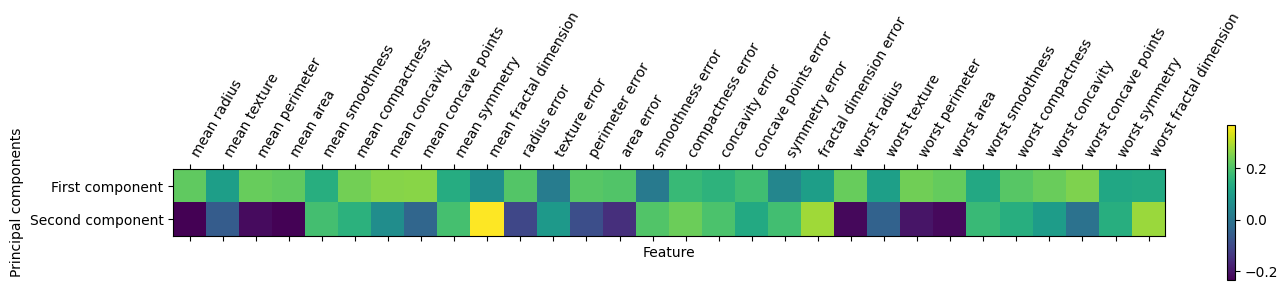

In [13]:
# ===== 书 3.4.1 节：components_ 属性与热图 =====
print("PCA component shape: {}".format(pca.components_.shape))
print("PCA components:\n{}".format(pca.components_))

plt.matshow(pca.components_, cmap='viridis')
plt.yticks([0, 1], ["First component", "Second component"])
plt.colorbar()
plt.xticks(range(len(cancer.feature_names)),
           cancer.feature_names, rotation=60, ha='left')
plt.xlabel("Feature")
plt.ylabel("Principal components")

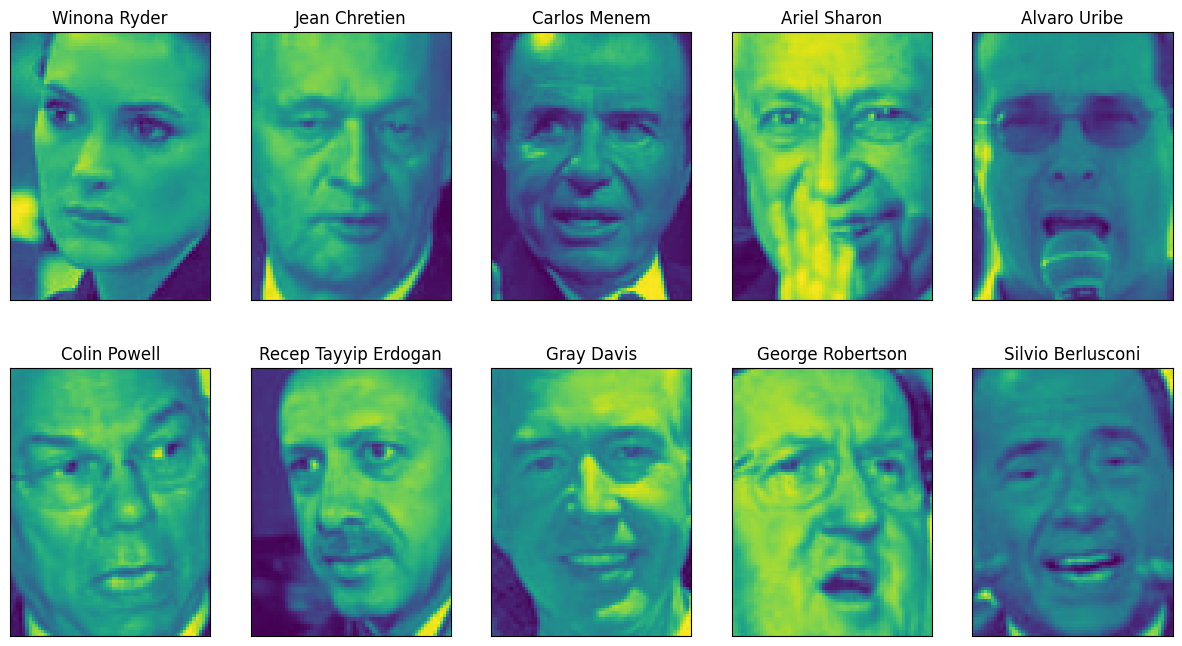

In [14]:
# ===== 书 3.4.1 节：加载 LFW 人脸数据 =====
from sklearn.datasets import fetch_lfw_people
people = fetch_lfw_people(min_faces_per_person=20, resize=0.7)

image_shape = people.images[0].shape

fix, axes = plt.subplots(2, 5, figsize=(15, 8),
                         subplot_kw={'xticks': (), 'yticks': ()})
for target, image, ax in zip(people.target, people.images, axes.ravel()):
    ax.imshow(image)
    ax.set_title(people.target_names[target])

In [15]:
# ===== 书 3.4.1 节：每人最多 50 张 =====
mask = np.zeros(people.target.shape, dtype=np.bool)
for target in np.unique(people.target):
    mask[np.where(people.target == target)[0][:50]] = 1

X_people = people.data[mask]
y_people = people.target[mask]

# 将灰度值缩放到0到1之间，而不是在0到255之间
# 以得到更好的数据稳定性
X_people = X_people / 255.

In [16]:
# ===== 书 3.4.1 节：原始像素上的 1-NN =====
from sklearn.neighbors import KNeighborsClassifier
# 将数据分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X_people, y_people, stratify=y_people, random_state=0)
# 使用一个邻居构建KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)
print("Test set score of 1-nn: {:.2f}".format(knn.score(X_test, y_test)))

Test set score of 1-nn: 0.18


In [17]:
# ===== 书 3.4.1 节：白化 PCA 变换 + 1-NN =====
pca = PCA(n_components=100, whiten=True, random_state=0).fit(X_train)
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)
print("X_train_pca.shape: {}".format(X_train_pca.shape))   # (1547, 100)

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train_pca, y_train)
print("Test set accuracy: {:.2f}".format(knn.score(X_test_pca, y_test)))

X_train_pca.shape: (1547, 100)
Test set accuracy: 0.23


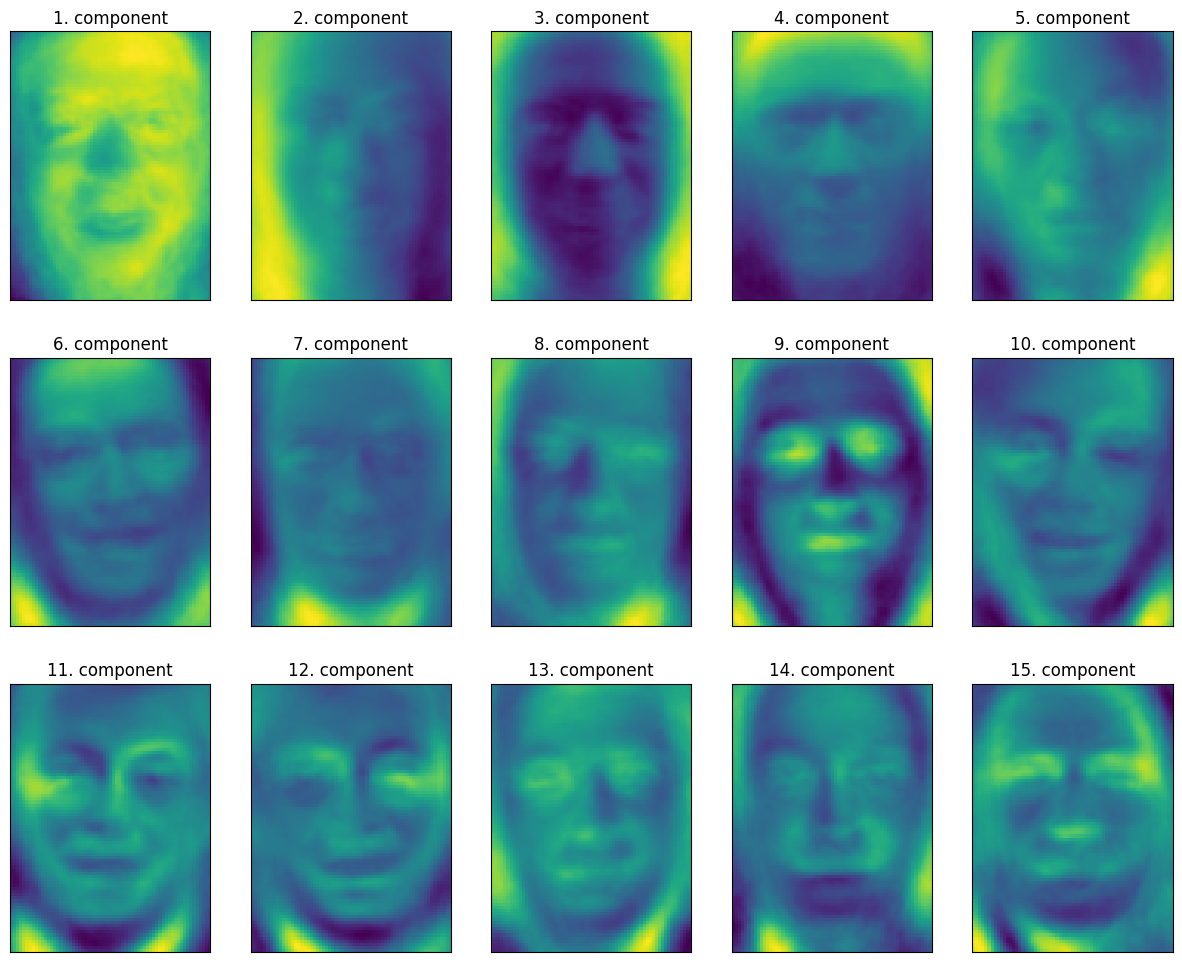

In [18]:
# ===== 书 3.4.1 节：绘制前 15 个特征脸 =====
fix, axes = plt.subplots(3, 5, figsize=(15, 12),
                         subplot_kw={'xticks': (), 'yticks': ()})
for i, (component, ax) in enumerate(zip(pca.components_, axes.ravel())):
    ax.imshow(component.reshape(image_shape),
              cmap='viridis')
    ax.set_title("{}. component".format((i + 1)))

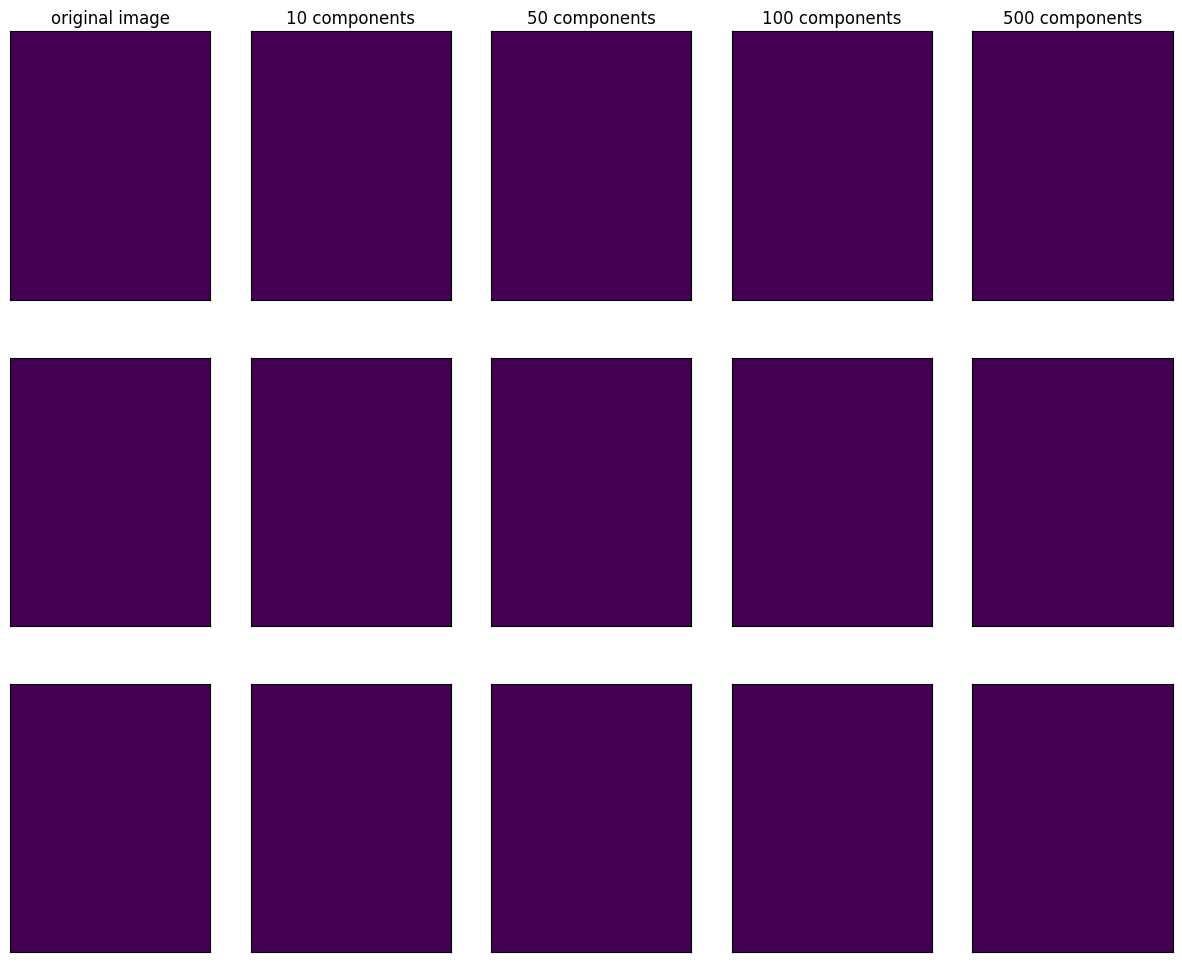

In [19]:
# ===== 书 3.4.1 节：用不同成分数重建人脸 =====
mglearn.plots.plot_pca_faces(X_train, X_test, image_shape)

### 3.4.2 非负矩阵分解

**非负矩阵分解（non-negative matrix factorization, NMF）**是另一种无监督学习算法，目的同样是提取有用的特征，工作原理类似 PCA，也可以降维。与 PCA 相同，NMF 把每个数据点写成**一些分量的加权求和**。区别在约束：

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\decomposition\_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


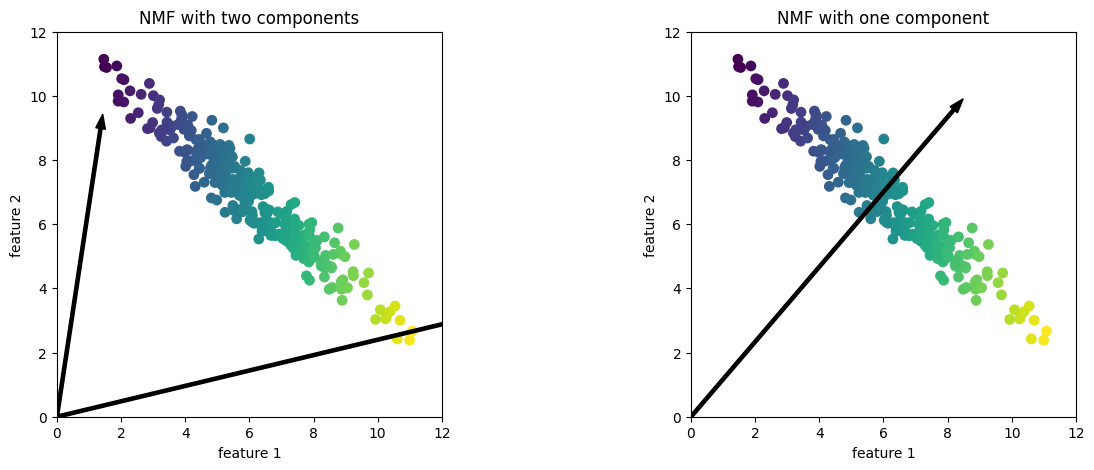

In [20]:
# ===== 书 3.4.2 节：NMF 图解 =====
mglearn.plots.plot_nmf_illustration()

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\decomposition\_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


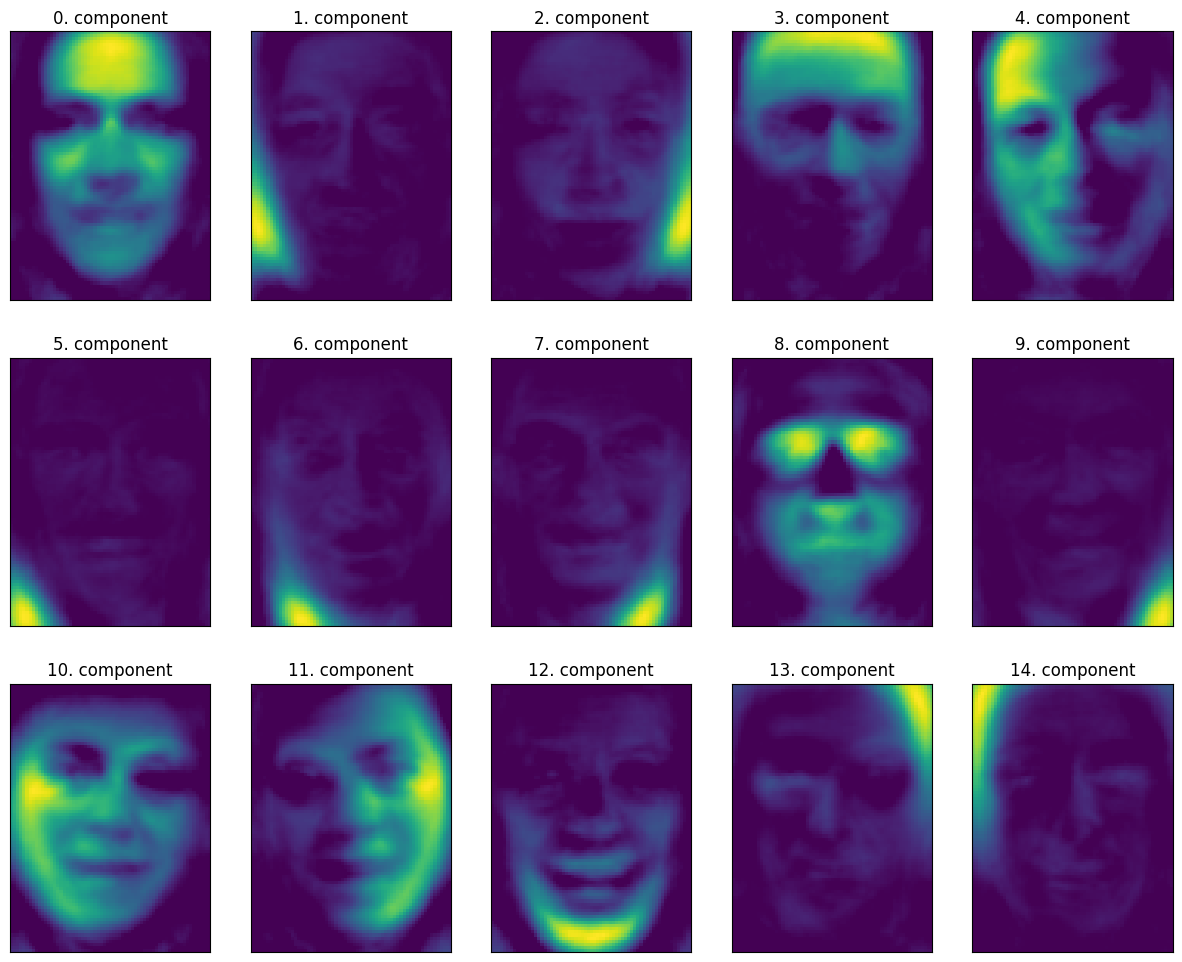

In [21]:
# ===== 书 3.4.2 节：15 个分量的 NMF =====
from sklearn.decomposition import NMF
nmf = NMF(n_components=15, random_state=0)
nmf.fit(X_train)
X_train_nmf = nmf.transform(X_train)
X_test_nmf = nmf.transform(X_test)

fix, axes = plt.subplots(3, 5, figsize=(15, 12),
                         subplot_kw={'xticks': (), 'yticks': ()})
for i, (component, ax) in enumerate(zip(nmf.components_, axes.ravel())):
    ax.imshow(component.reshape(image_shape))
    ax.set_title("{}. component".format(i))

Shape of measurements: (2000, 100)


Recovered signal shape: (2000, 3)


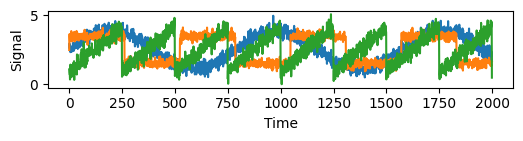

In [22]:
# ===== 书 3.4.2 节：信号源、混合与还原 =====
S = mglearn.datasets.make_signals()      # 三个原始信号源
plt.figure(figsize=(6, 1))
plt.plot(S, '-')
plt.xlabel("Time")
plt.ylabel("Signal")

# 将数据混合成100维的状态（100 台测量装置的观测）
A = np.random.RandomState(0).uniform(size=(100, 3))
X = np.dot(S, A.T)
print("Shape of measurements: {}".format(X.shape))       # (2000, 100)

# 用NMF来还原这三个信号
nmf = NMF(n_components=3, random_state=42)
S_ = nmf.fit_transform(X)
print("Recovered signal shape: {}".format(S_.shape))     # (2000, 3)

# 为了对比，也应用了PCA
pca = PCA(n_components=3)
H = pca.fit_transform(X)

# 并排绘制：观测 / 真实源 / NMF 还原 / PCA 还原（原书图 3-19）
models = [X, S, S_, H]
names = ['Observations (first three measurements)',
         'True sources',
         'NMF recovered signals',
         'PCA recovered signals']

### 3.4.3 用 t-SNE 进行流形学习

PCA 通常是变换数据的首选，但它的性质（**先旋转然后减少方向**）限制了它在可视化上的有效性——人脸数据的散点图（图 3-12）就是例子。有一类专用于可视化的算法叫**流形学习算法（manifold learning algorithm）**，允许更复杂的映射，通常给出更好的可视化。其中特别有用的一个是 **t-SNE**。

Text(0, 0.5, 'Second principal component')

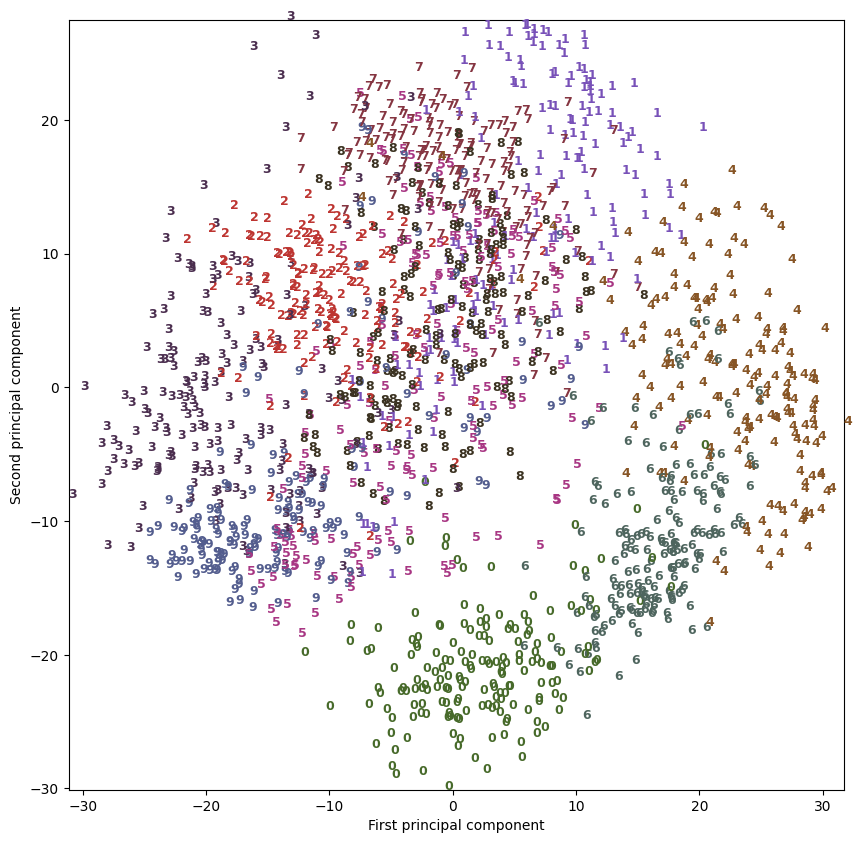

In [23]:
# ===== 书 3.4.3 节：PCA 降维 digits =====
from sklearn.datasets import load_digits
digits = load_digits()

# 构建一个PCA模型
pca = PCA(n_components=2)
pca.fit(digits.data)
# 将digits数据变换到前两个主成分的方向上
digits_pca = pca.transform(digits.data)
colors = ["#476A2A", "#7851B8", "#BD3430", "#4A2D4E", "#875525",
          "#A83683", "#4E655E", "#853541", "#3A3120", "#535D8E"]
plt.figure(figsize=(10, 10))
plt.xlim(digits_pca[:, 0].min(), digits_pca[:, 0].max())
plt.ylim(digits_pca[:, 1].min(), digits_pca[:, 1].max())
for i in range(len(digits.data)):
    # 将数据实际绘制成文本，而不是散点
    plt.text(digits_pca[i, 0], digits_pca[i, 1], str(digits.target[i]),
             color = colors[digits.target[i]],
             fontdict={'weight': 'bold', 'size': 9})
plt.xlabel("First principal component")
plt.ylabel("Second principal component")

Text(0.5, 0, 't-SNE feature 1')

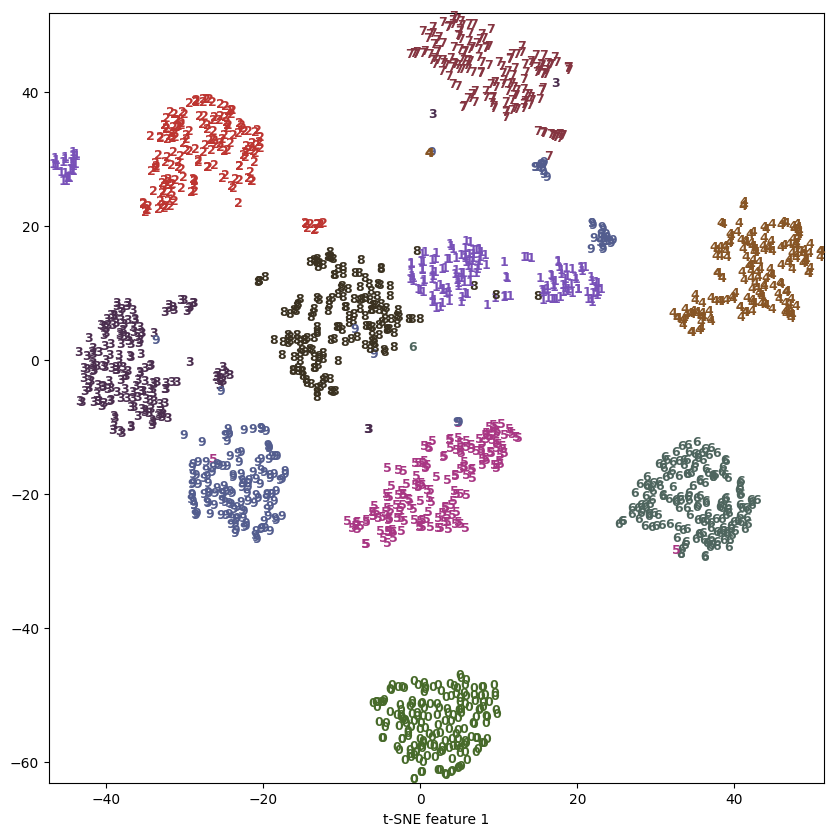

In [24]:
# ===== 书 3.4.3 节：t-SNE 变换与绘图 =====
from sklearn.manifold import TSNE
tsne = TSNE(random_state=42)
# 使用fit_transform而不是fit，因为TSNE没有transform方法
digits_tsne = tsne.fit_transform(digits.data)

plt.figure(figsize=(10, 10))
plt.xlim(digits_tsne[:, 0].min(), digits_tsne[:, 0].max() + 1)
plt.ylim(digits_tsne[:, 1].min(), digits_tsne[:, 1].max() + 1)
for i in range(len(digits.data)):
    # 将数据实际绘制成文本，而不是散点
    plt.text(digits_tsne[i, 0], digits_tsne[i, 1], str(digits.target[i]),
             color = colors[digits.target[i]],
             fontdict={'weight': 'bold', 'size': 9})
plt.xlabel("t-SNE feature 0")
plt.xlabel("t-SNE feature 1")

## 3.5 聚类

**聚类（clustering）**是将数据集划分成组的任务，这些组叫作**簇（cluster）**。目标是划分数据，使得**一个簇内的数据点非常相似、不同簇内的数据点非常不同**。与分类算法类似，聚类算法为每个数据点分配（或预测）一个数字，表示这个点属于哪个簇——但这个数字本身没有先验意义。

### 3.5.1 k均值聚类

k 均值聚类是最简单也最常用的聚类算法之一。它试图找到代表数据特定区域的**簇中心（cluster center）**。算法交替执行两个步骤：

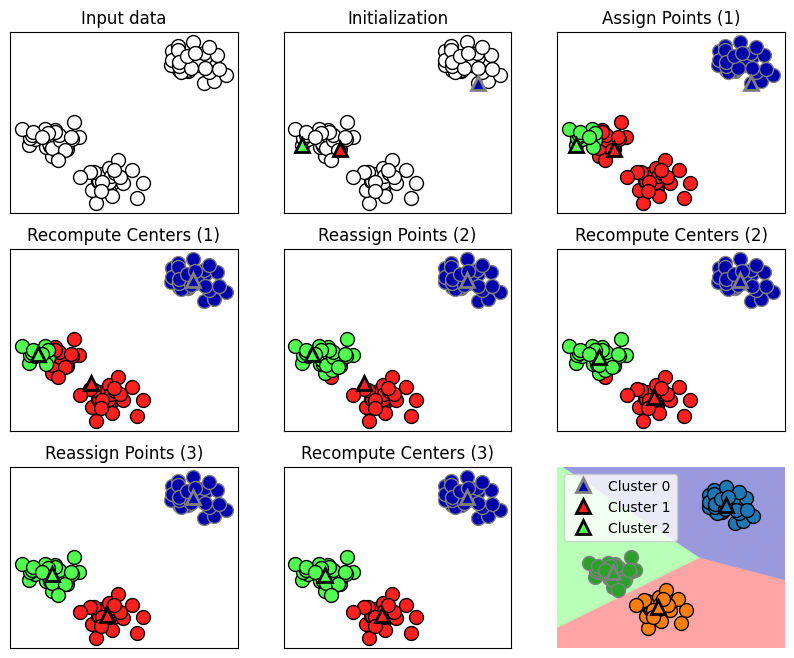

In [25]:
# ===== 书 3.5.1 节：k 均值算法步骤与簇边界图解 =====
mglearn.plots.plot_kmeans_algorithm()     # 图 3-23：算法的三个步骤
mglearn.plots.plot_kmeans_boundaries()    # 图 3-24：簇中心和簇边界

In [26]:
# ===== 书 3.5.1 节：KMeans 基本用法 =====
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 生成模拟的二维数据
X, y = make_blobs(random_state=1)

# 构建聚类模型
kmeans = KMeans(n_clusters=3)
kmeans.fit(X)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [27]:
# ===== 书 3.5.1 节：labels_ 属性 =====
print("Cluster memberships:\n{}".format(kmeans.labels_))

Cluster memberships:
[1 0 0 0 2 2 2 0 1 1 0 0 2 1 2 2 2 1 0 0 2 0 2 1 0 2 2 1 1 2 1 1 2 1 0 2 0
 0 0 2 2 0 1 0 0 2 1 1 1 1 0 2 2 2 1 2 0 0 1 1 0 2 2 0 0 2 1 2 1 0 0 0 2 1
 1 0 2 2 1 0 1 0 0 2 1 1 1 1 0 1 2 1 1 0 0 2 2 1 2 1]


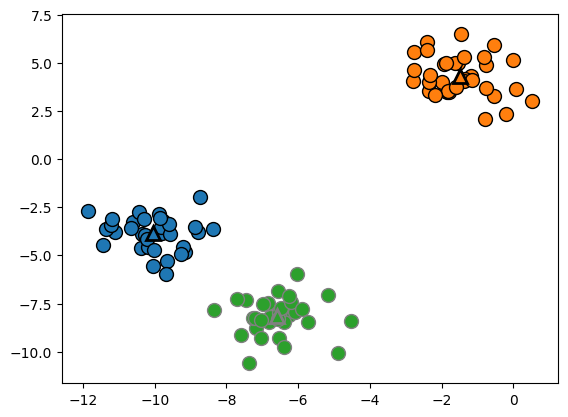

In [28]:
# ===== 书 3.5.1 节：画出簇分配与簇中心 =====
mglearn.discrete_scatter(X[:, 0], X[:, 1], kmeans.labels_, markers='o')
mglearn.discrete_scatter(
    kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], [0, 1, 2],
    markers='^', markeredgewidth=2)

Text(0, 0.5, 'Feature 1')

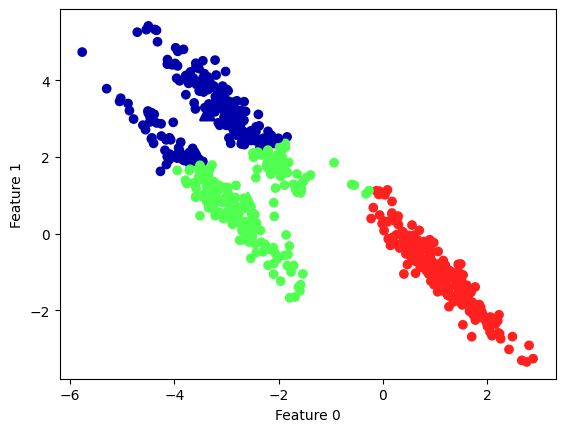

In [29]:
# ===== 书 3.5.1 节：拉长（非球形）的簇 =====
# 生成一些随机分组数据
X, y = make_blobs(random_state=170, n_samples=600)
rng = np.random.RandomState(74)

# 变换数据使其拉长
transformation = rng.normal(size=(2, 2))
X = np.dot(X, transformation)

# 将数据聚类成3个簇
kmeans = KMeans(n_clusters=3)
kmeans.fit(X)
y_pred = kmeans.predict(X)

# 画出簇分配和簇中心
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap=mglearn.cm3)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            marker='^', c=[0, 1, 2], s=100, linewidth=2, cmap=mglearn.cm3)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

Text(0, 0.5, 'Feature 1')

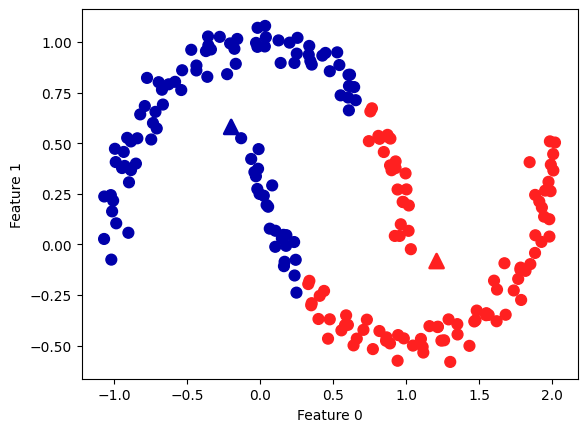

In [30]:
# ===== 书 3.5.1 节：two_moons 上的 k 均值 =====
# 生成模拟的two_moons数据（这次的噪声较小）
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=200, noise=0.05, random_state=0)

# 将数据聚类成2个簇
kmeans = KMeans(n_clusters=2)
kmeans.fit(X)
y_pred = kmeans.predict(X)

# 画出簇分配和簇中心
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap=mglearn.cm2, s=60)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            marker='^', c=[mglearn.cm2(0), mglearn.cm2(1)], s=100, linewidth=2)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

In [31]:
# ===== 书 3.5.1 节：三种方法的 100 分量重建 =====
X_train, X_test, y_train, y_test = train_test_split(
    X_people, y_people, stratify=y_people, random_state=0)
nmf = NMF(n_components=100, random_state=0)
nmf.fit(X_train)
pca = PCA(n_components=100, random_state=0)
pca.fit(X_train)
kmeans = KMeans(n_clusters=100, random_state=0)
kmeans.fit(X_train)

X_reconstructed_pca = pca.inverse_transform(pca.transform(X_test))
X_reconstructed_kmeans = kmeans.cluster_centers_[kmeans.predict(X_test)]
X_reconstructed_nmf = np.dot(nmf.transform(X_test), nmf.components_)
# （原书接着用两组网格图绘制"提取的分量"与"重建结果"，对应图 3-30 与图 3-31）

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\decomposition\_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


Distance feature shape: (200, 10)
Distance features:
[[0.53664613 1.15017588 0.93237626 ... 1.48034956 0.002907   1.07736639]
 [1.74138152 0.60592307 1.00666225 ... 2.52921971 1.20779969 2.23716489]
 [0.75710543 1.93145038 0.91586549 ... 0.78321505 0.87573753 0.71838465]
 ...
 [0.9274342  1.73811046 0.57899268 ... 1.11471941 0.83358544 1.04125672]
 [0.3227627  1.97647071 1.47861069 ... 0.81425026 0.84551232 0.28446737]
 [1.63322944 0.47226506 1.02289983 ... 2.46626118 1.09767675 2.14812753]]


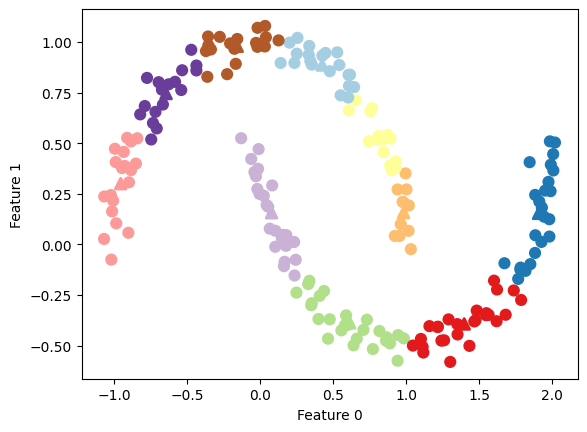

In [32]:
# ===== 书 3.5.1 节：10 个簇的矢量量化 + 距离特征 =====
X, y = make_moons(n_samples=200, noise=0.05, random_state=0)

kmeans = KMeans(n_clusters=10, random_state=0)
kmeans.fit(X)
y_pred = kmeans.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_pred, s=60, cmap='Paired')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=60,
            marker='^', c=range(kmeans.n_clusters), linewidth=2, cmap='Paired')
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

# 将到每个簇中心的距离作为特征，用 kmeans 的 transform 方法
distance_features = kmeans.transform(X)
print("Distance feature shape: {}".format(distance_features.shape))
print("Distance features:\n{}".format(distance_features))

### 3.5.2 凝聚聚类

**凝聚聚类（agglomerative clustering）**指许多基于相同原则构建的聚类算法：**算法首先声明每个点是自己的簇，然后合并两个最相似的簇，直到满足某种停止准则**。scikit-learn 中实现的停止准则是**簇的个数**——相似的簇被合并，直到仅剩下指定个数的簇。

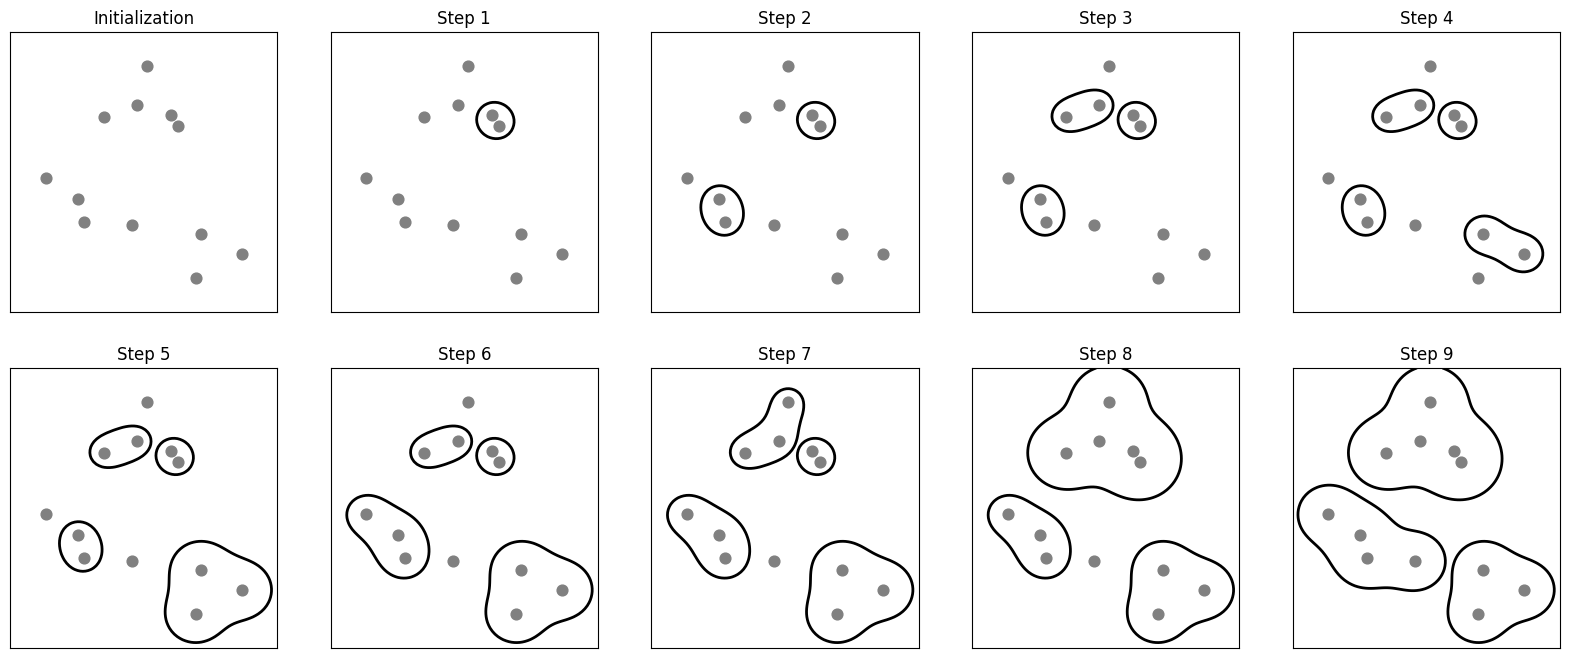

In [33]:
# ===== 书 3.5.2 节：凝聚过程图解 =====
mglearn.plots.plot_agglomerative_algorithm()

Text(0, 0.5, 'Feature 1')

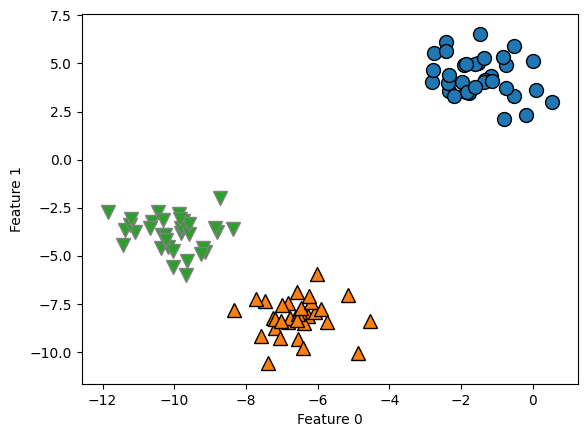

In [34]:
# ===== 书 3.5.2 节：AgglomerativeClustering 用法 =====
from sklearn.cluster import AgglomerativeClustering
X, y = make_blobs(random_state=1)

agg = AgglomerativeClustering(n_clusters=3)
assignment = agg.fit_predict(X)

mglearn.discrete_scatter(X[:, 0], X[:, 1], assignment)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")   # 原书图 3-34：3 个簇的分配结果，完美聚类

Text(0, 0.5, 'Cluster distance')

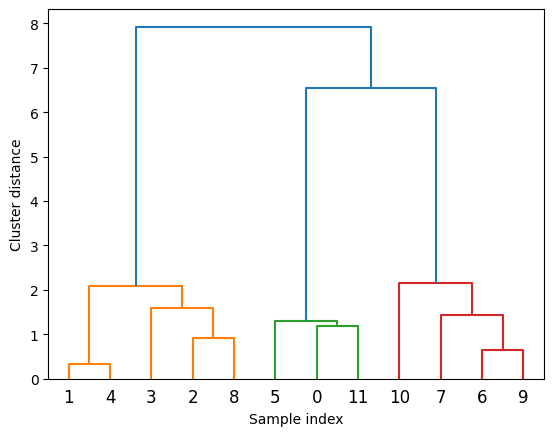

In [35]:
# ===== 书 3.5.2 节：SciPy 树状图 =====
# 从SciPy中导入dendrogram函数和ward聚类函数
from scipy.cluster.hierarchy import dendrogram, ward

X, y = make_blobs(random_state=0, n_samples=12)
# 将ward聚类应用于数据数组X
# SciPy的ward函数返回一个数组，指定执行凝聚聚类时跨越的距离
linkage_array = ward(X)
# 现在为包含簇之间距离的linkage_array绘制树状图
dendrogram(linkage_array)

# 在树中用虚线标记划分成两个簇（y=7.25）或三个簇（y=4）的位置，
# 并在虚线右端标注文字（原书用 ax.plot + ax.text 实现，此处从略）
ax = plt.gca()
bounds = ax.get_xbound()
plt.xlabel("Sample index")
plt.ylabel("Cluster distance")

### 3.5.3 DBSCAN

另一个非常有用的聚类算法是 **DBSCAN**——"density-based spatial clustering of applications with noise"（具有噪声的基于密度的空间聚类应用）的缩写。相比前两种算法，它的主要优点：

In [36]:
# ===== 书 3.5.3 节：默认参数的 DBSCAN =====
from sklearn.cluster import DBSCAN
X, y = make_blobs(random_state=0, n_samples=12)

dbscan = DBSCAN()
clusters = dbscan.fit_predict(X)
print("Cluster memberships:\n{}".format(clusters))

Cluster memberships:
[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]


Text(0, 0.5, 'Feature 1')

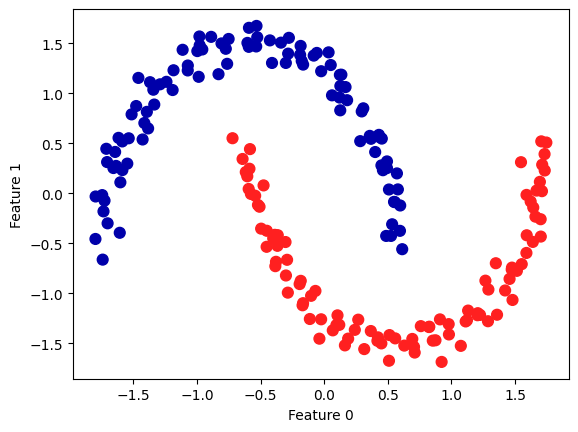

In [37]:
# ===== 书 3.5.3 节：two_moons 上的 DBSCAN =====
X, y = make_moons(n_samples=200, noise=0.05, random_state=0)

# 将数据缩放成平均值为0、方差为1
scaler = StandardScaler()
scaler.fit(X)
X_scaled = scaler.transform(X)

dbscan = DBSCAN()
clusters = dbscan.fit_predict(X_scaled)
# 绘制簇分配
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=clusters, cmap=mglearn.cm2, s=60)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

### 3.5.4 聚类算法的对比与评估

应用聚类算法的一大挑战：**很难评估一个算法的效果好坏，也很难比较不同算法的结果**。看完三种算法的原理，下面在现实世界的数据集上比较它们。

In [38]:
# ===== 书 3.5.4 节：ARI 比较三种聚类 =====
from sklearn.metrics.cluster import adjusted_rand_score
X, y = make_moons(n_samples=200, noise=0.05, random_state=0)

# 将数据缩放成平均值为0、方差为1
scaler = StandardScaler()
scaler.fit(X)
X_scaled = scaler.transform(X)

# 列出要使用的算法
algorithms = [KMeans(n_clusters=2), AgglomerativeClustering(n_clusters=2),
              DBSCAN()]

# 创建一个随机的簇分配，作为参考
random_state = np.random.RandomState(seed=0)
random_clusters = random_state.randint(low=0, high=2, size=len(X))

print("Random assignment ARI: {:.2f}".format(
    adjusted_rand_score(y, random_clusters)))
for algorithm in algorithms:
    clusters = algorithm.fit_predict(X_scaled)
    print("{} ARI: {:.2f}".format(algorithm.__class__.__name__,
                                  adjusted_rand_score(y, clusters)))
    # （原书此处将每种算法的簇分配画成四联小图，对应图 3-39）

Random assignment ARI: 0.00
KMeans ARI: 0.50
AgglomerativeClustering ARI: 0.61
DBSCAN ARI: 1.00


In [39]:
# ===== 书 3.5.4 节：accuracy_score 的陷阱 =====
from sklearn.metrics import accuracy_score

# 这两种点标签对应于相同的聚类
clusters1 = [0, 0, 1, 1, 0]
clusters2 = [1, 1, 0, 0, 1]
# 精度为0，因为二者标签完全不同
print("Accuracy: {:.2f}".format(accuracy_score(clusters1, clusters2)))
# 调整rand分数为1，因为二者聚类完全相同
print("ARI: {:.2f}".format(adjusted_rand_score(clusters1, clusters2)))

Accuracy: 0.00
ARI: 1.00


In [40]:
# ===== 书 3.5.4 节：人脸数据的特征脸表示 =====
# 从lfw数据中提取特征脸，并对数据进行变换
from sklearn.decomposition import PCA
pca = PCA(n_components=100, whiten=True, random_state=0)
pca.fit_transform(X_people)
X_pca = pca.transform(X_people)

In [41]:
# ===== 书 3.5.4 节：DBSCAN 参数调整 =====
# 应用默认参数的DBSCAN → Unique labels: [-1]
dbscan = DBSCAN()
labels = dbscan.fit_predict(X_pca)

# 减小 min_samples=3 → Unique labels: [-1]（仍然全噪声）
dbscan = DBSCAN(min_samples=3)
labels = dbscan.fit_predict(X_pca)

# 增大 eps=15 → 出现单一簇和噪声点
dbscan = DBSCAN(min_samples=3, eps=15)
labels = dbscan.fit_predict(X_pca)
print("Unique labels: {}".format(np.unique(labels)))

# 计算所有簇中的点数和噪声中的点数。
# bincount不允许负值，所以我们需要加1。
# 结果中的第一个数字对应于噪声点。
print("Number of points per cluster: {}".format(np.bincount(labels + 1)))

Unique labels: [-1  0]
Number of points per cluster: [  17 2046]


In [42]:
# ===== 书 3.5.4 节：eps 扫描 =====
for eps in [1, 3, 5, 7, 9, 11, 13]:
    print("\neps={}".format(eps))
    dbscan = DBSCAN(eps=eps, min_samples=3)
    labels = dbscan.fit_predict(X_pca)
    print("Clusters present: {}".format(np.unique(labels)))
    print("Cluster sizes: {}".format(np.bincount(labels + 1)))


eps=1
Clusters present: [-1]
Cluster sizes: [2063]

eps=3
Clusters present: [-1]
Cluster sizes: [2063]

eps=5
Clusters present: [-1]
Cluster sizes: [2063]

eps=7
Clusters present: [-1  0  1  2  3  4]
Cluster sizes: [1995   54    4    4    3    3]

eps=9
Clusters present: [-1  0]
Cluster sizes: [1313  750]

eps=11
Clusters present: [-1  0]
Cluster sizes: [ 455 1608]

eps=13
Clusters present: [-1  0]
Cluster sizes: [  94 1969]


In [43]:
# ===== 书 3.5.4 节：k 均值聚人脸 =====
# 用k均值提取簇
km = KMeans(n_clusters=10, random_state=0)
labels_km = km.fit_predict(X_pca)
print("Cluster sizes k-means: {}".format(np.bincount(labels_km)))

Cluster sizes k-means: [  2 502 324 343 126 175 386   2 155  48]


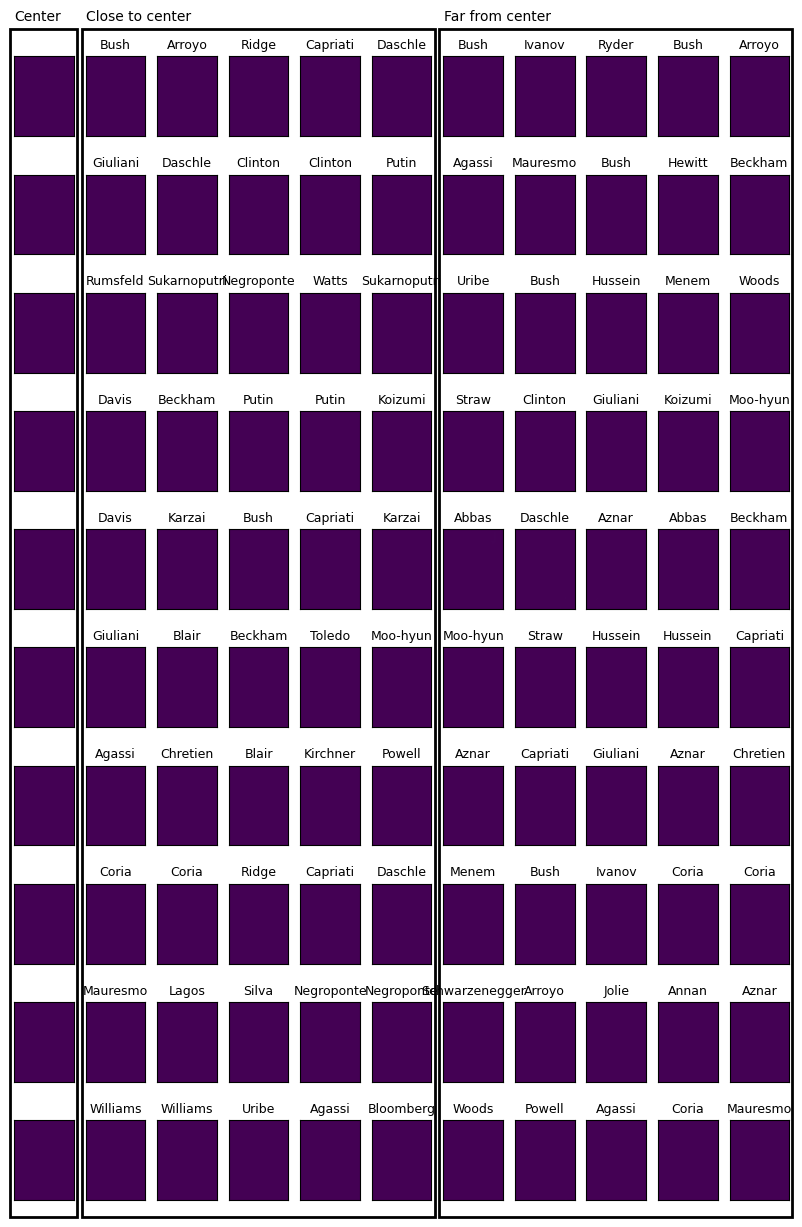

In [44]:
# ===== 书 3.5.4 节：典型与非典型人脸 =====
mglearn.plots.plot_kmeans_faces(km, pca, X_pca, X_people,
                                y_people, people.target_names)

In [45]:
# ===== 书 3.5.4 节：凝聚聚类聚人脸 =====
# 用ward凝聚聚类提取簇
agglomerative = AgglomerativeClustering(n_clusters=10)
labels_agg = agglomerative.fit_predict(X_pca)
print("Cluster sizes agglomerative clustering: {}".format(
    np.bincount(labels_agg)))
# → [255 623  86 102 122 199 265  26 230 155]

# 用 ARI 度量凝聚聚类和 k 均值给出的两种数据划分是否相似
print("ARI: {:.2f}".format(adjusted_rand_score(labels_agg, labels_km)))

Cluster sizes agglomerative clustering: [288 102 302 797 107  67  43  59 106 192]
ARI: 0.07


Text(0, 0.5, 'Cluster distance')

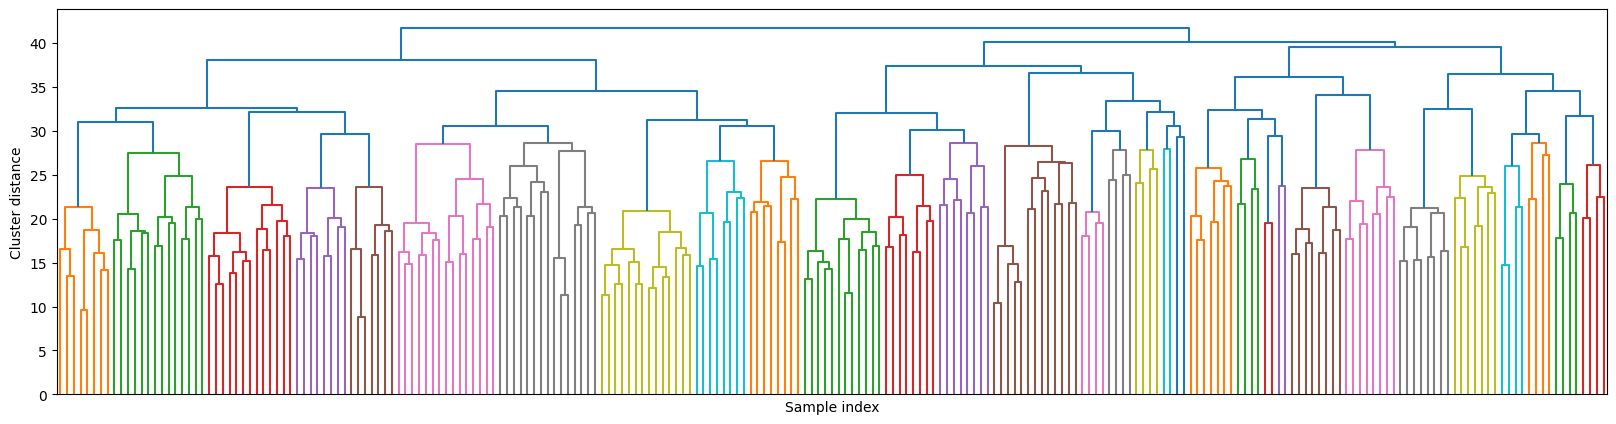

In [46]:
# ===== 书 3.5.4 节：人脸数据的树状图 =====
linkage_array = ward(X_pca)
# 现在我们为包含簇之间距离的linkage_array绘制树状图
plt.figure(figsize=(20, 5))
dendrogram(linkage_array, p=7, truncate_mode='level', no_labels=True)
plt.xlabel("Sample index")
plt.ylabel("Cluster distance")   # 原书图 3-45

### 3.5.5 聚类方法小结

本节内容表明：**聚类的应用与评估是一个非常定性的过程**，通常在数据分析的探索阶段很有帮助。三种聚类算法都可以控制聚类的**粒度（granularity）**：k 均值和凝聚聚类允许指定想要的簇的数量，DBSCAN 允许用 eps 参数定义接近程度从而间接影响簇的大小。三种方法都可以用于大型现实数据集，都相对容易理解，也都可以聚类成多个簇。

## 3.6 小结与展望

本章介绍了一系列无监督学习算法，可用于**探索性数据分析**和**预处理**。找到数据的正确表示对监督学习和无监督学习的成功都至关重要，预处理和分解方法在数据准备中具有重要作用。

In [47]:
# ===== 书 3.6 节 侧栏：估计器接口 =====
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()